# Physical and biological response to wind event 

## Diatom response

Code reused from https://github.com/SalishSeaCast/analysis-junqi/blob/main/Analysis_Storm_Bio_Response/Report_D%26F_Section.ipynb.

In [2]:
# files

# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"


EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

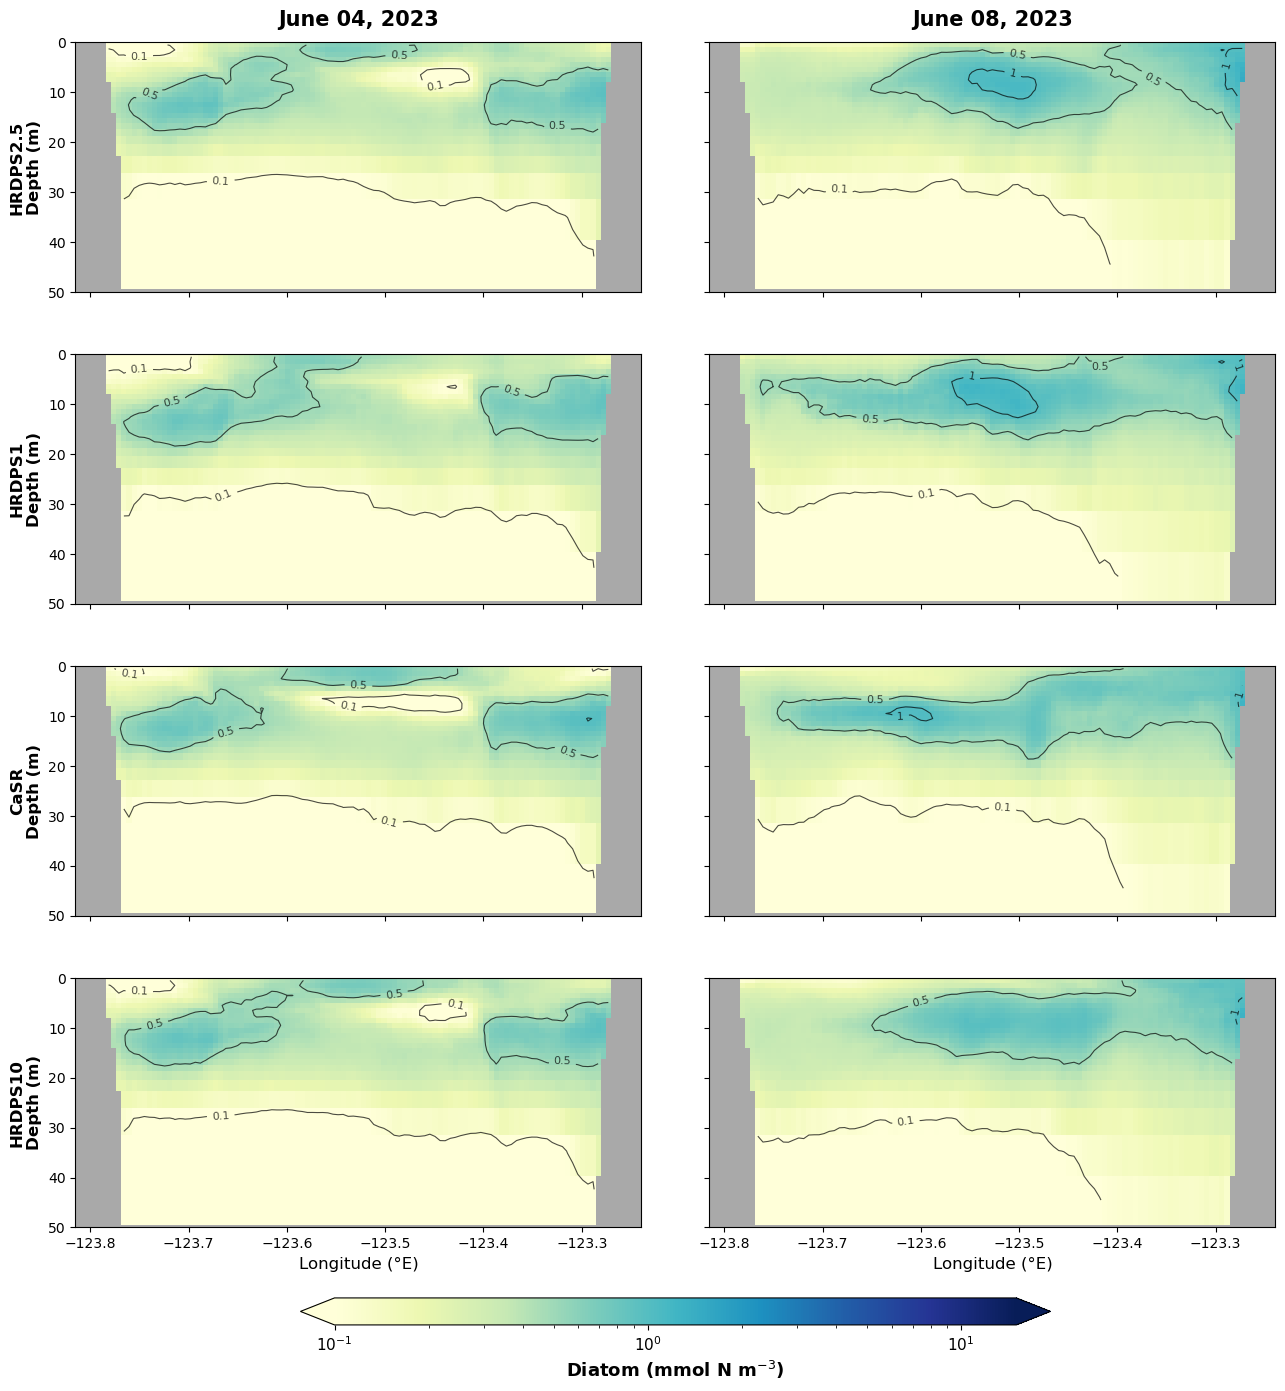

In [4]:

# Bio_Section_Plot_2023_CentralSoG.py
# 2023 June 4 and June 8
# Diatom vertical sections at Central SoG
# 4 experiments x 2 dates

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# configure

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Central Strait of Georgia
Y_CENTER = 475
X_CENTER = 275

# East-West section
LEFT_OFFSET = 50
RIGHT_OFFSET = 60

DEPTH_LIMIT = 50

# Diatom color scale
VMIN = 0.1
VMAX = 15
CONTOUR_LEVELS = [0.1, 0.5, 1, 2, 5, 10]

CMAP = "YlGnBu"

OUTPUT_FILE = "Diatom_CentralSoG_June2023_4x2.png"


# load

def load_diatom_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_biol_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # Time coordinate
        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        # Match target date
        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # Depth
        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # Longitude and latitude
        lon_2d = np.ma.filled(
            ds.variables["nav_lon"][:], np.nan
        )

        lat_2d = np.ma.filled(
            ds.variables["nav_lat"][:], np.nan
        )

        # Section range
        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)
        x_end = min(nx, X_CENTER + RIGHT_OFFSET + 1)

        x_slice = slice(x_start, x_end)

        # Extract diatoms
        diatom = ds.variables["diatoms"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        diatom = np.ma.masked_invalid(diatom)
        diatom = np.ma.masked_less_equal(diatom, 0)

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]

    return diatom, lon_sec, lat_sec, depths[:nz]


# visualize

def plot_section(ax, diatom, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        diatom,
        norm=LogNorm(vmin=VMIN, vmax=VMAX),
        cmap=CMAP,
        shading="auto"
    )

    # Contours
    valid = np.ma.compressed(diatom)

    if valid.size > 0:
        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:
            cs = ax.contour(
                X,
                Z,
                diatom,
                levels=levels,
                colors="black",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf




def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_diatom_section(
                model,
                date_obj
            )

            if result is None:
                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )
                continue

            diatom, lon, lat, depths = result

            cf = plot_section(
                ax,
                diatom,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:
                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:
                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:
                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # colorbar

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25, 0.065, 0.50, 0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            extend="both"
        )

        cbar.set_label(
            "Diatom (mmol N m$^{-3}$)",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(labelsize=11)



    plt.show()




if __name__ == "__main__":
    main()


## Salinity response

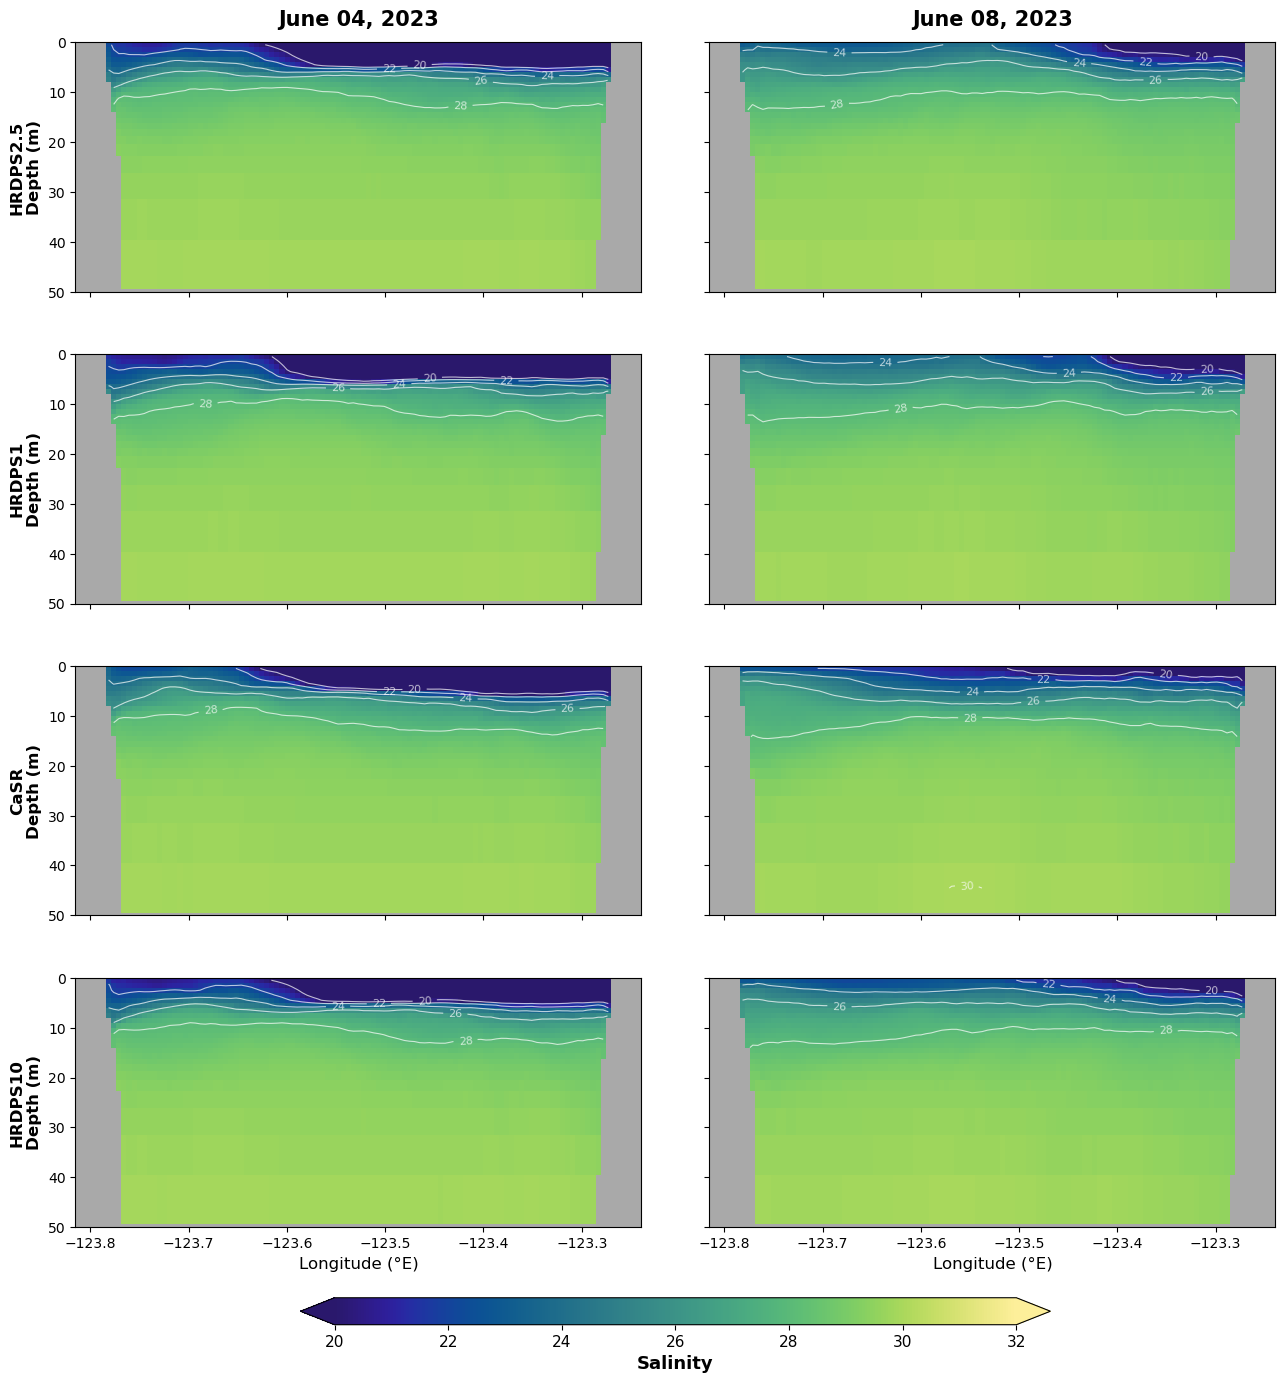

In [9]:

# Salinity_Section_Plot_2023_CentralSoG.py
# 2023 June 4 and June 8
# Diatom vertical sections at Central SoG
# 4 experiments x 2 dates

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import cmocean
from matplotlib.colors import Normalize

# configure

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Central Strait of Georgia
Y_CENTER = 475
X_CENTER = 275

# East-West section
LEFT_OFFSET = 50
RIGHT_OFFSET = 60

DEPTH_LIMIT = 50

# Diatom color scale
VMIN = 20
VMAX = 32
# CONTOUR_LEVELS = [0.1, 0.5, 1, 2, 5, 10]
CONTOUR_LEVELS = [20, 22, 24, 26, 28, 30, 32]

CMAP = cmocean.cm.haline


# load

def load_salinity_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_grid_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # Time coordinate
        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        # Match target date
        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # Depth
        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # Longitude and latitude
        lon_2d = np.ma.filled(
            ds.variables["nav_lon"][:], np.nan
        )

        lat_2d = np.ma.filled(
            ds.variables["nav_lat"][:], np.nan
        )

        # Section range
        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)
        x_end = min(nx, X_CENTER + RIGHT_OFFSET + 1)

        x_slice = slice(x_start, x_end)

        # Extract salinity
        diatom = ds.variables["vosaline"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        diatom = np.ma.masked_invalid(diatom)
        diatom = np.ma.masked_less_equal(diatom, 0)

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]

    return diatom, lon_sec, lat_sec, depths[:nz]


# visualize

def plot_section(ax, diatom, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        diatom,
        #norm=LogNorm(vmin=VMIN, vmax=VMAX),
        norm=Normalize(vmin=VMIN, vmax=VMAX),
        cmap=CMAP,
        shading="auto"
    )

    # Contours
    valid = np.ma.compressed(diatom)

    if valid.size > 0:
        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:
            cs = ax.contour(
                X,
                Z,
                diatom,
                levels=levels,
                colors="white",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf




def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_salinity_section(
                model,
                date_obj
            )

            if result is None:
                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )
                continue

            diatom, lon, lat, depths = result

            cf = plot_section(
                ax,
                diatom,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:
                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:
                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:
                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # colorbar

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25, 0.065, 0.50, 0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            extend="both"
        )

        cbar.set_label(
            "Salinity",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(labelsize=11)



    plt.show()




if __name__ == "__main__":
    main()

# 